In [7]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import pandas as pd
import umap
import kagglehub
import os
from tools import generate_plot

file_path = "fashion-mnist_test.csv"

dataset_path = kagglehub.dataset_download("zalando-research/fashionmnist")
print(f"Dane pobrane do: {dataset_path}")

csv_path = os.path.join(dataset_path, "fashion-mnist_test.csv")

df = pd.read_csv(csv_path)

clothes_dict = {
    0: 'T-shirt/top',
    1: 'Trouser',
    2: 'Pullover',
    3: 'Dress',
    4: 'Coat',
    5: 'Sandal',
    6: 'Shirt',
    7: 'Sneaker',
    8: 'Bag',
    9: 'Ankle boot'
}

labels = df['label']
df_pixel_only = df.drop('label',axis=1)
mapped_labels = labels.map(clothes_dict)

Dane pobrane do: C:\Users\jacek\.cache\kagglehub\datasets\zalando-research\fashionmnist\versions\4


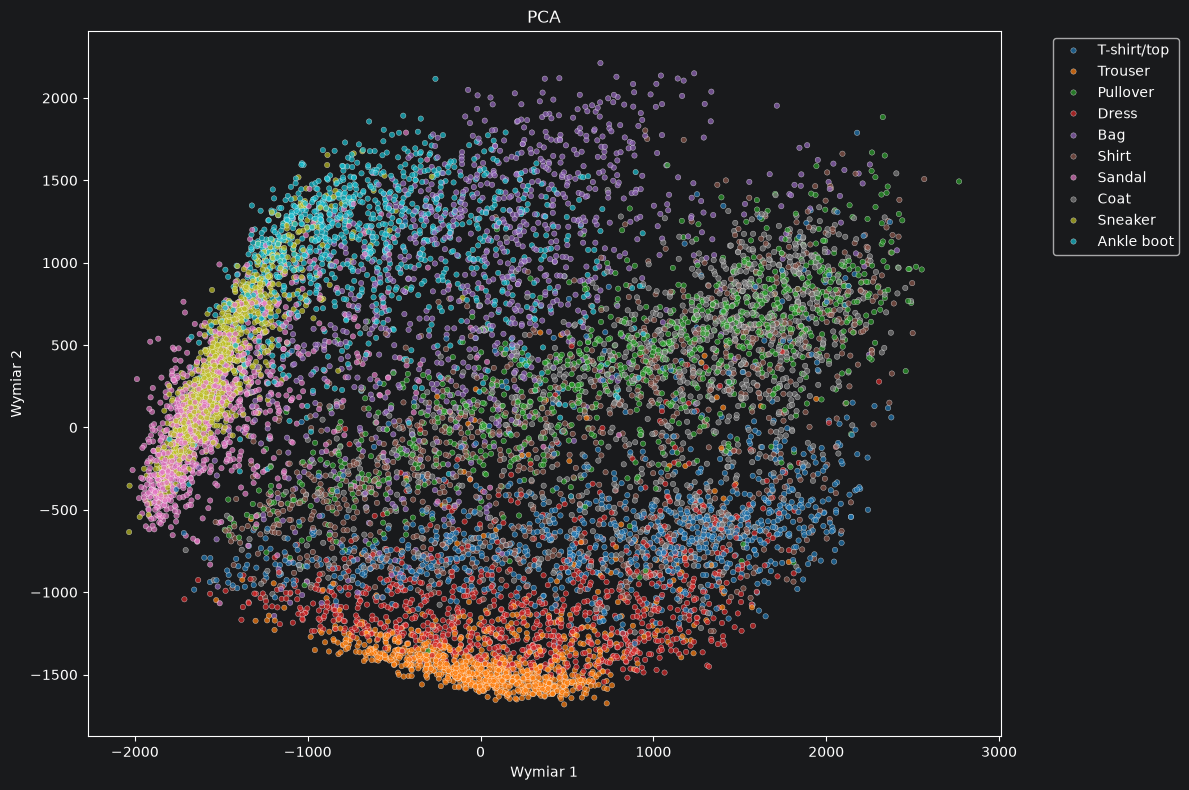

In [8]:
pca = PCA(n_components=2)
data_pca = pca.fit_transform(df_pixel_only)

generate_plot(data_pca, mapped_labels, 'PCA')


Z PCA nie można za dużo wywnioskować, widać że poszczególne typu ubrań grupują się w pewnych obszarach ale wykres tworzy jedną wielką chmurę

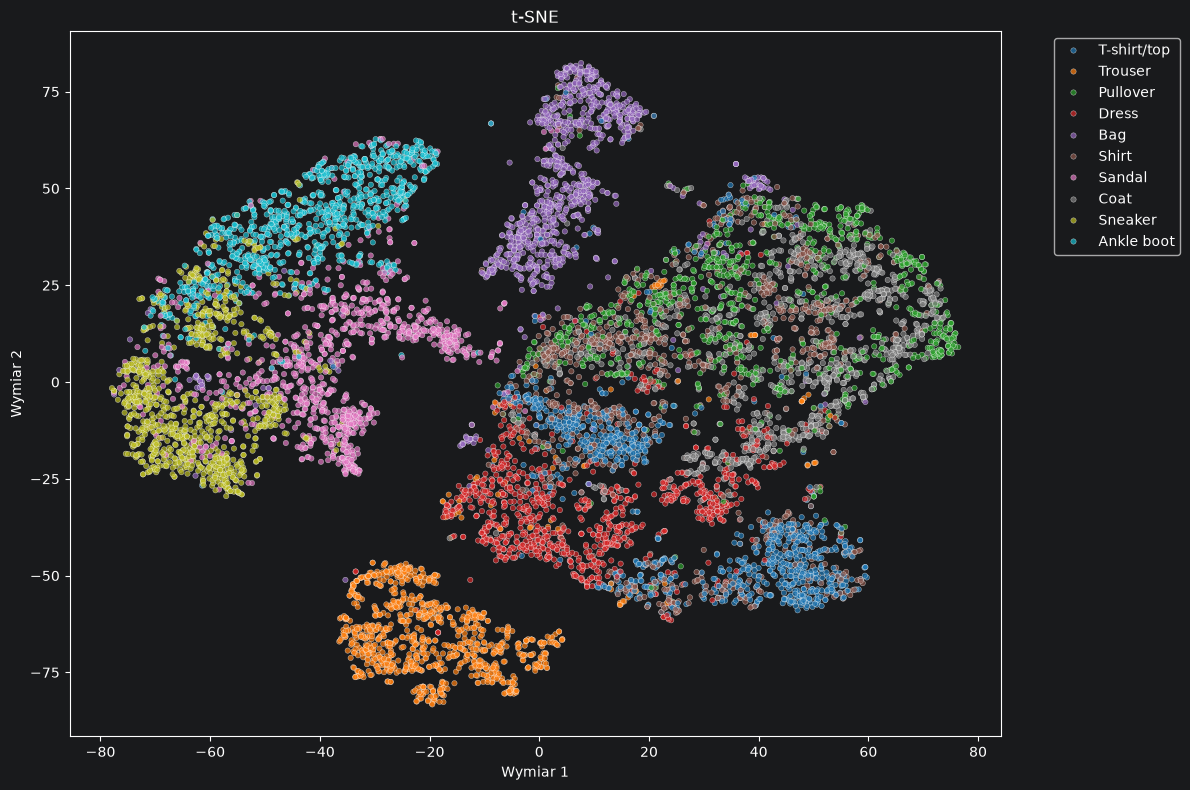

In [9]:
tsne = TSNE(n_components=2, perplexity=30.0, random_state=42)
tsne_data = tsne.fit_transform(df_pixel_only)

generate_plot(tsne_data, mapped_labels, 't-SNE')

C:\Users\jacek\DataMain\development\pwr\axion\axion-challenge\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


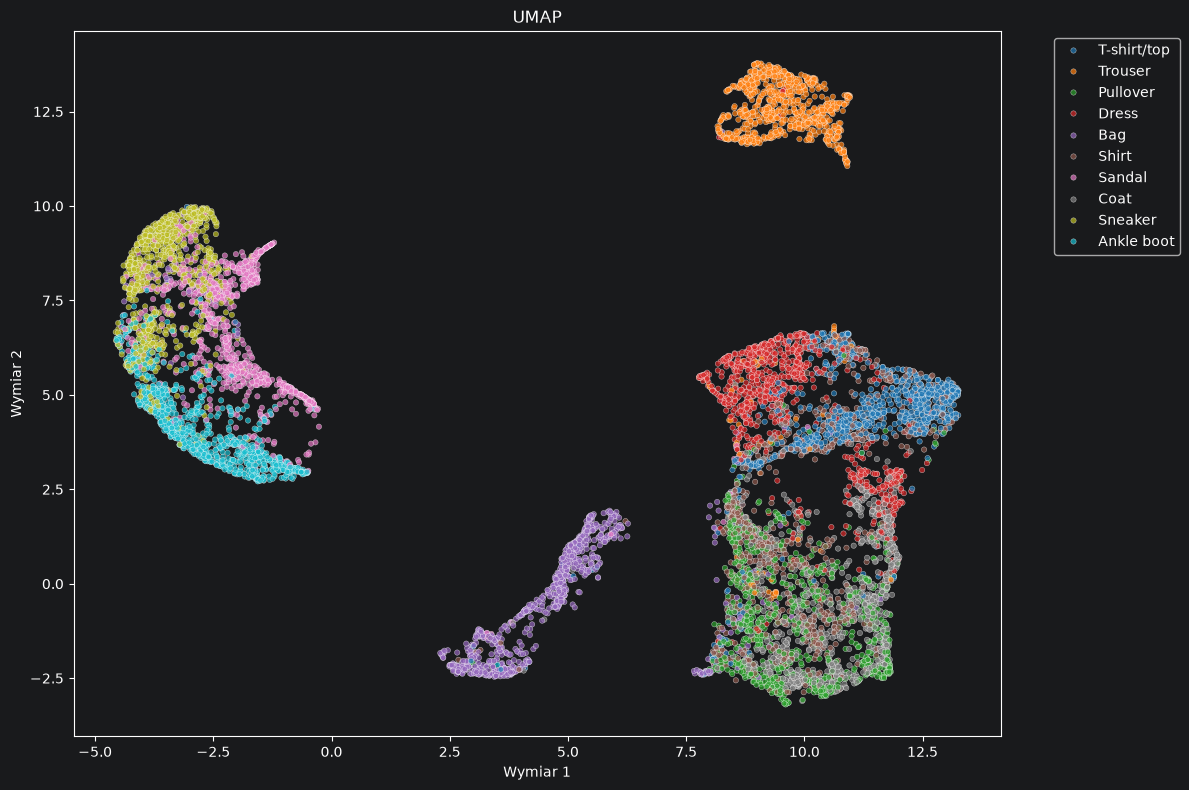

In [10]:
reducer = umap.UMAP(n_components=2, random_state=42)
umap_data = reducer.fit_transform(df_pixel_only)

generate_plot(umap_data,mapped_labels,'UMAP')


t-sne i umap dzielą dane na kilka różnych wysp. Największy problem bedzie z ubraniami typu: pullover, shirt, coat.

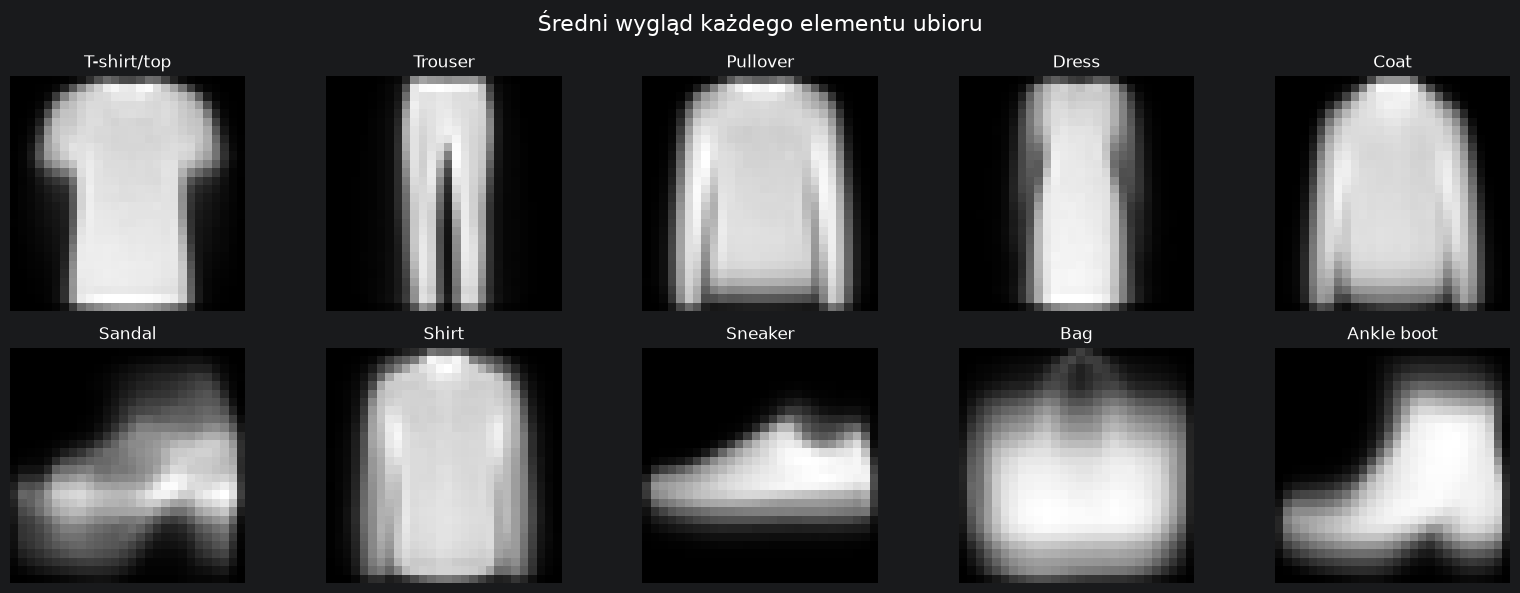

In [11]:
mean_by_class = df.groupby('label').mean()

fig, axes = plt.subplots(2, 5, figsize=(16, 6))

for label, ax in enumerate(axes.flat):
    pixels_vector = mean_by_class.loc[label].values
    pic_28x28 = pixels_vector.reshape(28, 28)


    ax.imshow(pic_28x28, cmap='gray')
    ax.set_title(clothes_dict[label])
    ax.axis('off')

plt.suptitle('Średni wygląd każdego elementu ubioru', fontsize=16)
plt.tight_layout()
plt.show()

tutaj widać że pullover coat i shirt faktycznie wyglądają w uśrednieniu bardzo podobnie, model będzie miał najwiekszy problem z rozpoznawaniem tych części ubrań. Wytrenuje dwa modele jeden bedzie kożystałem z bazowego datasetu, a drugi bedzie miał zmodyfikowany dataset tj. pullover coat i shit zostaną scalone do jednej super klasy. Jeśli accuracy drugiego modelu bedzie znacząco wyższe będzie to potwierdzeniem hipotezy.